In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Konfigurasi tampilan grafik
plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["axes.grid"] = True

print("Library berhasil diimport.")


Library berhasil diimport.


In [2]:
# Membaca dataset hasil preprocessing
# Lokasi file hasil preprocessing
DATA_PATH = Path("outputs/bearing_clean.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset tidak ditemukan: {DATA_PATH.resolve()}"
    )

# Membaca data sinyal
df = pd.read_csv(DATA_PATH)

print("Dataset berhasil dibaca!")
print(f"Jumlah baris : {len(df):,}")
print(f"Jumlah kolom : {len(df.columns)}")

display(df.head())


Dataset berhasil dibaca!
Jumlah baris : 4,815,787
Jumlah kolom : 9


,source_file,condition,defect_size_inch,motor_load_hp,original_fs_hz,sampling_rate_hz,sample_index,time_seconds,vibration
0,97.mat,Normal,NaN,0,48000,12000,0,0.000000,0.055947
1,97.mat,Normal,NaN,0,48000,12000,1,0.000083,0.015231
2,97.mat,Normal,NaN,0,48000,12000,2,0.000167,-0.079317
3,97.mat,Normal,NaN,0,48000,12000,3,0.000250,0.045434
4,97.mat,Normal,NaN,0,48000,12000,4,0.000333,0.047412


In [9]:
# 
# Memeriksa kolom dan tipe data
print("Daftar kolom:")
print(df.dtypes)

print("\nDistribusi kondisi bearing:")
print(df["condition"].value_counts())

print("\nJumlah rekaman per kondisi:")
print(
    df.groupby("condition")["source_file"].nunique()
)

print("\nFrekuensi sampling:")
print(df["sampling_rate_hz"].unique())


Daftar kolom:
source_file          object
condition            object
defect_size_inch    float64
motor_load_hp         int64
original_fs_hz        int64
sampling_rate_hz      int64
sample_index          int64
time_seconds        float64
vibration           float64
dtype: object

Distribusi kondisi bearing:
condition
Outer Race    1464906
Ball Fault    1463166
Inner Race    1463077
Normal         424638
Name: count, dtype: int64

Jumlah rekaman per kondisi:
condition
Ball Fault    12
Inner Race    12
Normal         4
Outer Race    12
Name: source_file, dtype: int64

Frekuensi sampling:
[12000]


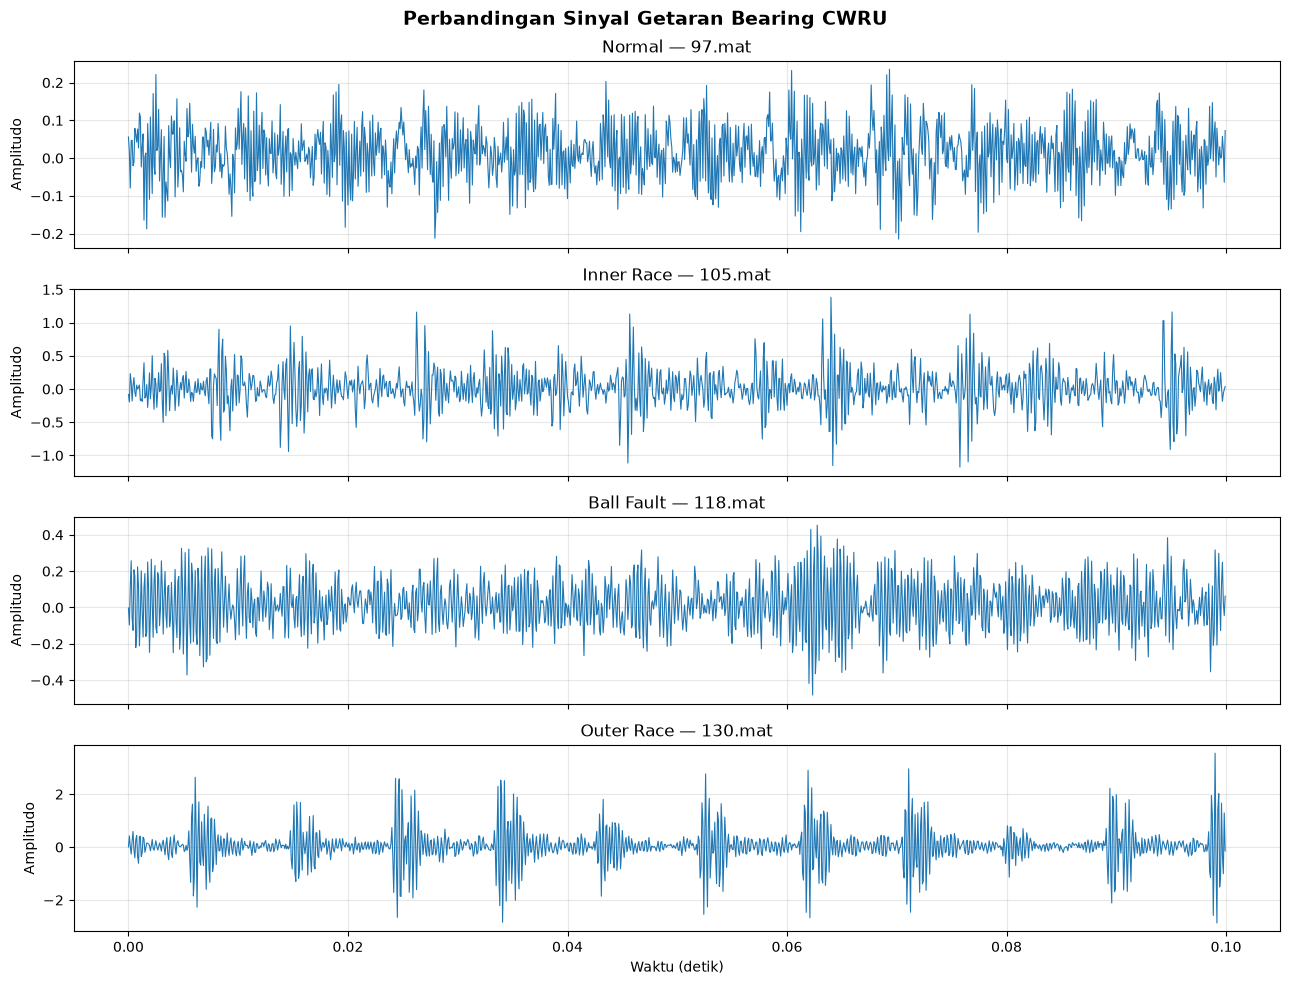

In [11]:
#  Visualisasi empat kondisi bearing
# Kondisi bearing yang akan dibandingkan
conditions = [
    "Normal",
    "Inner Race",
    "Ball Fault",
    "Outer Race"
]

sample_count = 1200

fig, axes = plt.subplots(
    4, 1,
    figsize=(13, 10),
    sharex=True
)

for ax, condition in zip(axes, conditions):

    # Pilih data sesuai kondisi dan beban 0 HP
    subset = df[
        (df["condition"] == condition) &
        (df["motor_load_hp"] == 0)
    ]

    if subset.empty:
        raise ValueError(
            f"Tidak ada data untuk {condition}, 0 HP."
        )

    # Pilih satu rekaman, jangan mencampur file
    source_file = subset["source_file"].iloc[0]

    signal_df = subset[
        subset["source_file"] == source_file
    ].sort_values("sample_index").head(sample_count)

    ax.plot(
        signal_df["time_seconds"],
        signal_df["vibration"],
        linewidth=0.8
    )

    ax.set_title(f"{condition} — {source_file}")
    ax.set_ylabel("Amplitudo")
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Waktu (detik)")

fig.suptitle(
    "Perbandingan Sinyal Getaran Bearing CWRU",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


In [5]:
# Statistik deskriptif awal

# Statistik amplitudo berdasarkan kondisi
summary = df.groupby("condition")["vibration"].agg(
    count="count",
    mean="mean",
    std="std",
    min="min",
    max="max"
)

display(summary)


,count,mean,std,min,max
condition,,,,,
Ball Fault,1463166,0.006529,0.137098,-1.963516,2.278153
Inner Race,1463077,0.008055,0.341044,-3.371747,3.787987
Normal,424638,0.012446,0.059698,-0.282216,0.282112
Outer Race,1464906,0.006164,0.482298,-6.653343,6.652937


# FILTERING SIGNAL

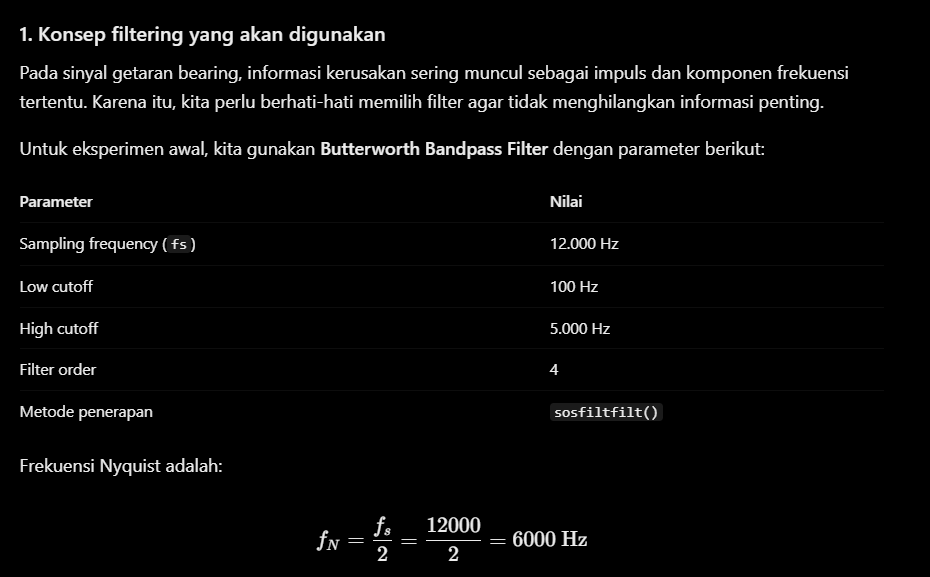

Jadi, rentang 100–5.000 Hz berada di bawah frekuensi Nyquist. Nilai cutoff ini merupakan konfigurasi awal eksperimen, bukan berarti sudah terbukti paling optimal untuk klasifikasi kerusakan.

In [12]:
# Membuat filter Butterworth
from scipy.signal import butter, sosfiltfilt, sosfreqz

# Parameter filter
FS = 12000
LOW_CUTOFF = 100
HIGH_CUTOFF = 5000
FILTER_ORDER = 4

# Membuat Butterworth Bandpass Filter
sos = butter(
    N=FILTER_ORDER,
    Wn=[LOW_CUTOFF, HIGH_CUTOFF],
    btype="bandpass",
    fs=FS,
    output="sos"
)

print("Filter Butterworth berhasil dibuat.")
print(f"Sampling rate : {FS} Hz")
print(f"Cutoff         : {LOW_CUTOFF} - {HIGH_CUTOFF} Hz")
print(f"Order          : {FILTER_ORDER}")


Filter Butterworth berhasil dibuat.
Sampling rate : 12000 Hz
Cutoff         : 100 - 5000 Hz
Order          : 4


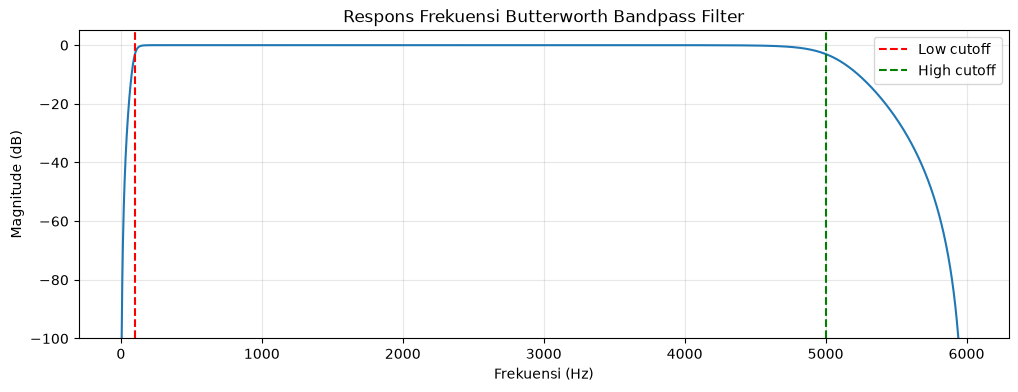

In [13]:
# Visualisasi respons frekuensi filter
# Menghitung respons frekuensi filter
freq, response = sosfreqz(sos, worN=4096, fs=FS)

magnitude_db = 20 * np.log10(
    np.maximum(np.abs(response), 1e-12)
)

plt.figure(figsize=(12, 4))
plt.plot(freq, magnitude_db)

plt.axvline(
    LOW_CUTOFF,
    color="red",
    linestyle="--",
    label="Low cutoff"
)

plt.axvline(
    HIGH_CUTOFF,
    color="green",
    linestyle="--",
    label="High cutoff"
)

plt.title("Respons Frekuensi Butterworth Bandpass Filter")
plt.xlabel("Frekuensi (Hz)")
plt.ylabel("Magnitude (dB)")
plt.ylim(-100, 5)
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [14]:
# Menerapkan filtering ke seluruh 40 file
# Pastikan dataset memiliki kolom yang dibutuhkan
required_columns = [
    "source_file",
    "sample_index",
    "sampling_rate_hz",
    "vibration"
]

missing = [
    col for col in required_columns
    if col not in df.columns
]

if missing:
    raise ValueError(f"Kolom tidak ditemukan: {missing}")

# Periksa nilai sampling rate
if not np.allclose(df["sampling_rate_hz"], FS):
    raise ValueError(
        "Sampling rate dataset tidak sesuai dengan konfigurasi filter."
    )

# Siapkan kolom hasil filtering
df["vibration_filtered"] = np.nan

# Proses setiap rekaman secara terpisah
for source_file, group in df.groupby("source_file", sort=False):

    group = group.sort_values("sample_index")
    signal = group["vibration"].to_numpy(dtype=float)

    if not np.isfinite(signal).all():
        raise ValueError(
            f"Nilai sinyal tidak valid pada {source_file}"
        )

    filtered_signal = sosfiltfilt(sos, signal)

    # Simpan hasil sesuai indeks baris aslinya
    df.loc[group.index, "vibration_filtered"] = filtered_signal

    print(f"Filtering selesai: {source_file}")

print("\nSeluruh rekaman berhasil difilter.")
print(f"Jumlah rekaman: {df['source_file'].nunique()}")


Filtering selesai: 97.mat
Filtering selesai: 98 .mat
Filtering selesai: 99.mat
Filtering selesai: 100.mat
Filtering selesai: 105.mat
Filtering selesai: 106.mat
Filtering selesai: 107.mat
Filtering selesai: 108.mat
Filtering selesai: 118.mat
Filtering selesai: 119.mat
Filtering selesai: 120.mat
Filtering selesai: 121.mat
Filtering selesai: 130.mat
Filtering selesai: 131.mat
Filtering selesai: 132.mat
Filtering selesai: 133.mat
Filtering selesai: 169.mat
Filtering selesai: 170.mat
Filtering selesai: 171.mat
Filtering selesai: 172.mat
Filtering selesai: 185.mat
Filtering selesai: 186.mat
Filtering selesai: 187.mat
Filtering selesai: 188.mat
Filtering selesai: 197.mat
Filtering selesai: 198.mat
Filtering selesai: 199.mat
Filtering selesai: 200.mat
Filtering selesai: 209.mat
Filtering selesai: 210.mat
Filtering selesai: 211.mat
Filtering selesai: 212.mat
Filtering selesai: 222.mat
Filtering selesai: 223.mat
Filtering selesai: 224.mat
Filtering selesai: 225.mat
Filtering selesai: 234.mat
Fil

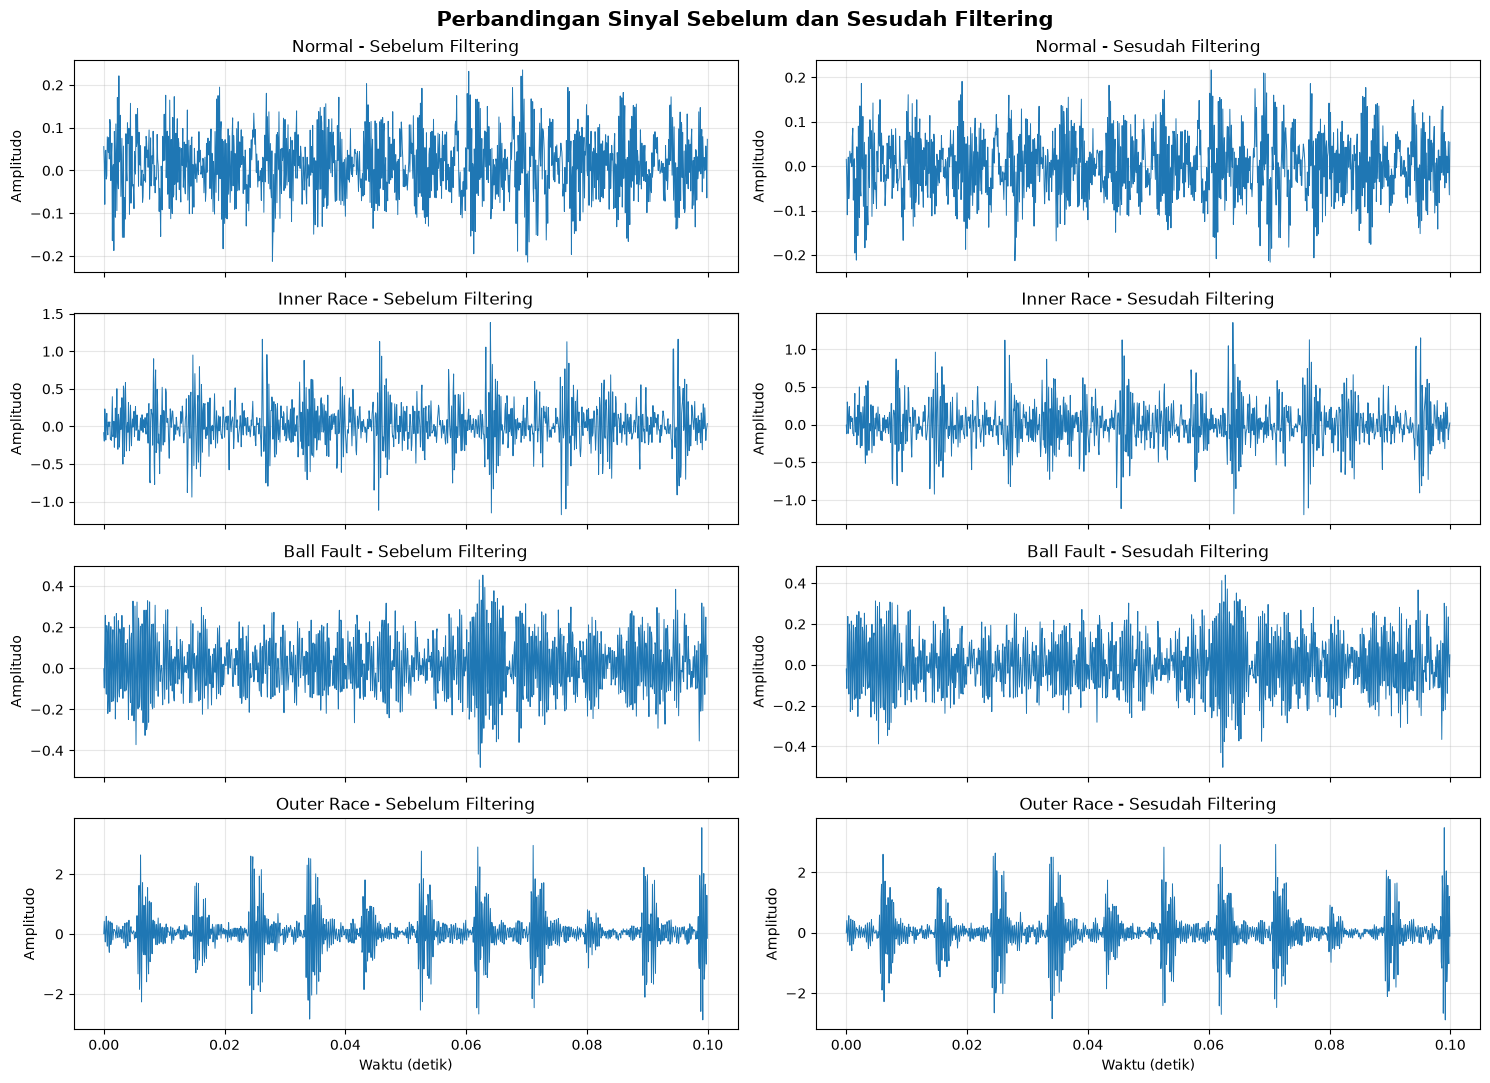

In [15]:
# Membandingkan sinyal sebelum dan sesudah filtering
conditions = [
    "Normal",
    "Inner Race",
    "Ball Fault",
    "Outer Race"
]

fig, axes = plt.subplots(
    4, 2,
    figsize=(15, 11),
    sharex=True
)

for i, condition in enumerate(conditions):

    subset = df[
        (df["condition"] == condition) &
        (df["motor_load_hp"] == 0)
    ]

    source_file = subset["source_file"].iloc[0]

    signal_df = (
        subset[subset["source_file"] == source_file]
        .sort_values("sample_index")
        .head(1200)
    )

    time = signal_df["time_seconds"]

    original = signal_df["vibration"]
    filtered = signal_df["vibration_filtered"]

    axes[i, 0].plot(time, original, linewidth=0.7)
    axes[i, 0].set_title(
        f"{condition} - Sebelum Filtering"
    )

    axes[i, 1].plot(time, filtered, linewidth=0.7)
    axes[i, 1].set_title(
        f"{condition} - Sesudah Filtering"
    )

    for ax in axes[i]:
        ax.set_ylabel("Amplitudo")
        ax.grid(alpha=0.3)

axes[-1, 0].set_xlabel("Waktu (detik)")
axes[-1, 1].set_xlabel("Waktu (detik)")

fig.suptitle(
    "Perbandingan Sinyal Sebelum dan Sesudah Filtering",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


In [16]:
# Menyimpan hasil filtering
OUTPUT_PATH = Path("outputs/bearing_filtered.csv")

OUTPUT_PATH.parent.mkdir(
    parents=True,
    exist_ok=True
)

df.to_csv(OUTPUT_PATH, index=False)

print(f"Dataset tersimpan: {OUTPUT_PATH.resolve()}")
print(f"Jumlah baris: {len(df):,}")
print(f"Jumlah rekaman: {df['source_file'].nunique()}")


Dataset tersimpan: D:\python\sem 5\Pemrosesan sinyal\Tugas Besar\outputs\bearing_filtered.csv
Jumlah baris: 4,815,787
Jumlah rekaman: 40


In [ ]:
# Evaluasi perubahan sinyal
# Evaluasi filtering berdasarkan empat rekaman contoh
results = []

for condition in conditions:
    subset = df[
        (df["condition"] == condition) &
        (df["motor_load_hp"] == 0)
    ]

    source_file = subset["source_file"].iloc[0]

    signal_df = subset[
        subset["source_file"] == source_file
    ].sort_values("sample_index")

    original = signal_df["vibration"].to_numpy()
    filtered = signal_df["vibration_filtered"].to_numpy()

    # RMS sebelum dan sesudah
    rms_before = np.sqrt(np.mean(original**2))
    rms_after = np.sqrt(np.mean(filtered**2))

    # Selisih RMS dalam persen
    rms_change = (
        (rms_after - rms_before) / rms_before
    ) * 100

    # RMS komponen yang berubah
    rms_difference = np.sqrt(
        np.mean((original - filtered)**2)
    )

    results.append({
        "Condition": condition,
        "RMS Before": rms_before,
        "RMS After": rms_after,
        "RMS Change (%)": rms_change,
        "RMS Difference": rms_difference
    })

evaluation_df = pd.DataFrame(results)

display(evaluation_df.round(5))


,Condition,RMS Before,RMS After,RMS Change (%),RMS Difference
0,Normal,0.07177,0.07000,-2.46251,0.01416
1,Inner Race,0.29153,0.29079,-0.25385,0.01705
2,Ball Fault,0.13923,0.13858,-0.47223,0.01304
3,Outer Race,0.66951,0.66643,-0.46002,0.05552


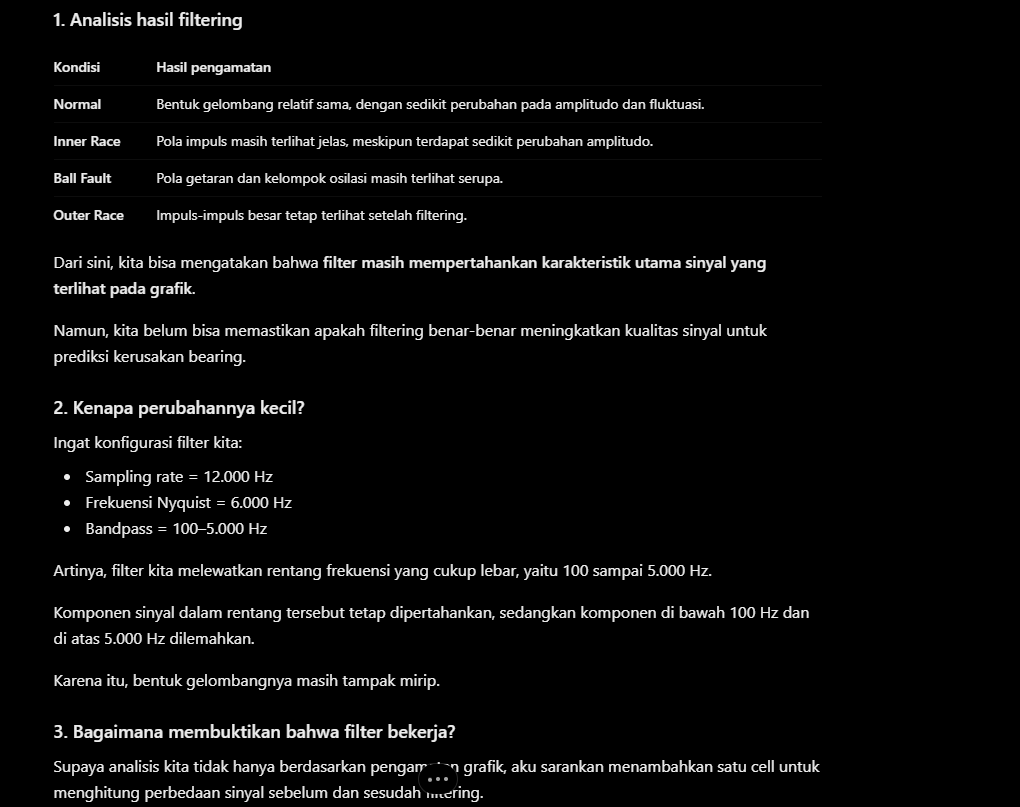

# Konvolusi dan Z-Transform

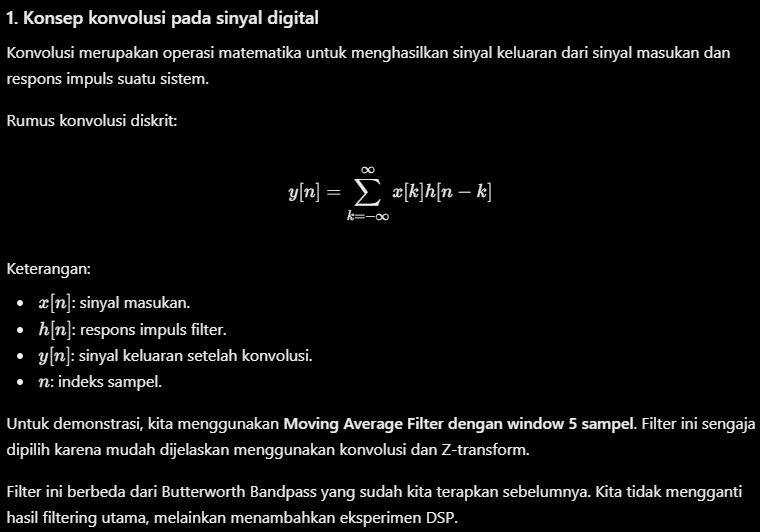

In [20]:
# Implementasi konvolusi
from scipy.signal import convolve

# Mengambil satu rekaman Normal
normal_df = (
    df[
        (df["condition"] == "Normal") &
        (df["motor_load_hp"] == 0)
    ]
    .sort_values(["source_file", "sample_index"])
)

source_file = normal_df["source_file"].iloc[0]

signal = (
    normal_df[normal_df["source_file"] == source_file]
    ["vibration"]
    .to_numpy()[:1200]
)

# Respons impuls Moving Average 5 sampel
window_size = 5
h = np.ones(window_size) / window_size

# Konvolusi diskrit
signal_convolved = convolve(
    signal,
    h,
    mode="full"
)

# Ambil bagian dengan panjang sama seperti input
signal_same = signal_convolved[
    :len(signal)
]

print("Respons impuls filter:", h)
print("Jumlah sampel input:", len(signal))
print("Jumlah sampel output:", len(signal_same))


Respons impuls filter: [0.2 0.2 0.2 0.2 0.2]
Jumlah sampel input: 1200
Jumlah sampel output: 1200


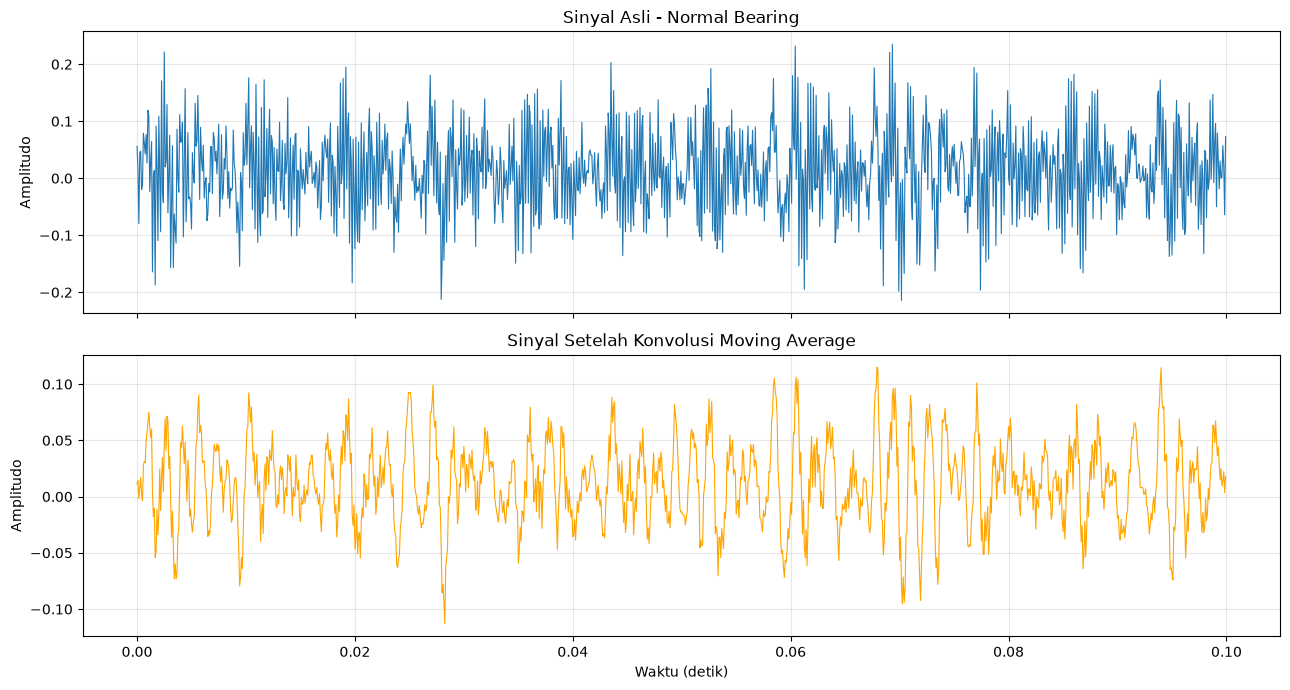

In [21]:
# Visualisasi hasil konvolusi
time = np.arange(len(signal)) / FS

fig, axes = plt.subplots(
    2, 1,
    figsize=(13, 7),
    sharex=True
)

axes[0].plot(
    time,
    signal,
    linewidth=0.8
)

axes[0].set_title("Sinyal Asli - Normal Bearing")
axes[0].set_ylabel("Amplitudo")

axes[1].plot(
    time,
    signal_same,
    linewidth=0.8,
    color="orange"
)

axes[1].set_title(
    "Sinyal Setelah Konvolusi Moving Average"
)
axes[1].set_ylabel("Amplitudo")
axes[1].set_xlabel("Waktu (detik)")

for ax in axes:
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


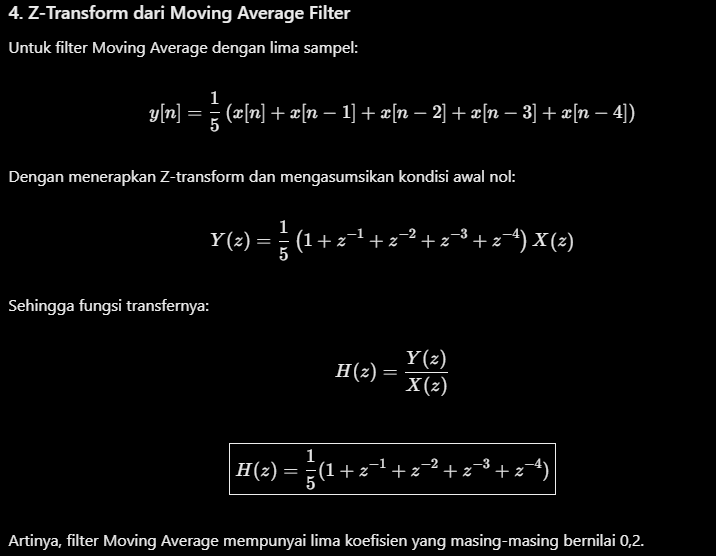

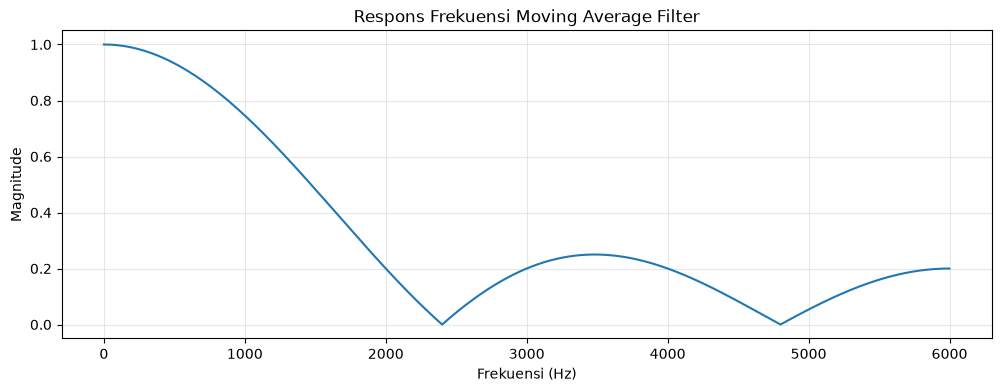

In [22]:
# Visualisasi respons frekuensi filter Moving Average
from scipy.signal import freqz

# Menghitung respons frekuensi
freq, H = freqz(
    h,
    worN=4096,
    fs=FS
)

magnitude = np.abs(H)

plt.figure(figsize=(12, 4))

plt.plot(
    freq,
    magnitude,
    linewidth=1.5
)

plt.title(
    "Respons Frekuensi Moving Average Filter"
)
plt.xlabel("Frekuensi (Hz)")
plt.ylabel("Magnitude")
plt.grid(alpha=0.3)
plt.show()


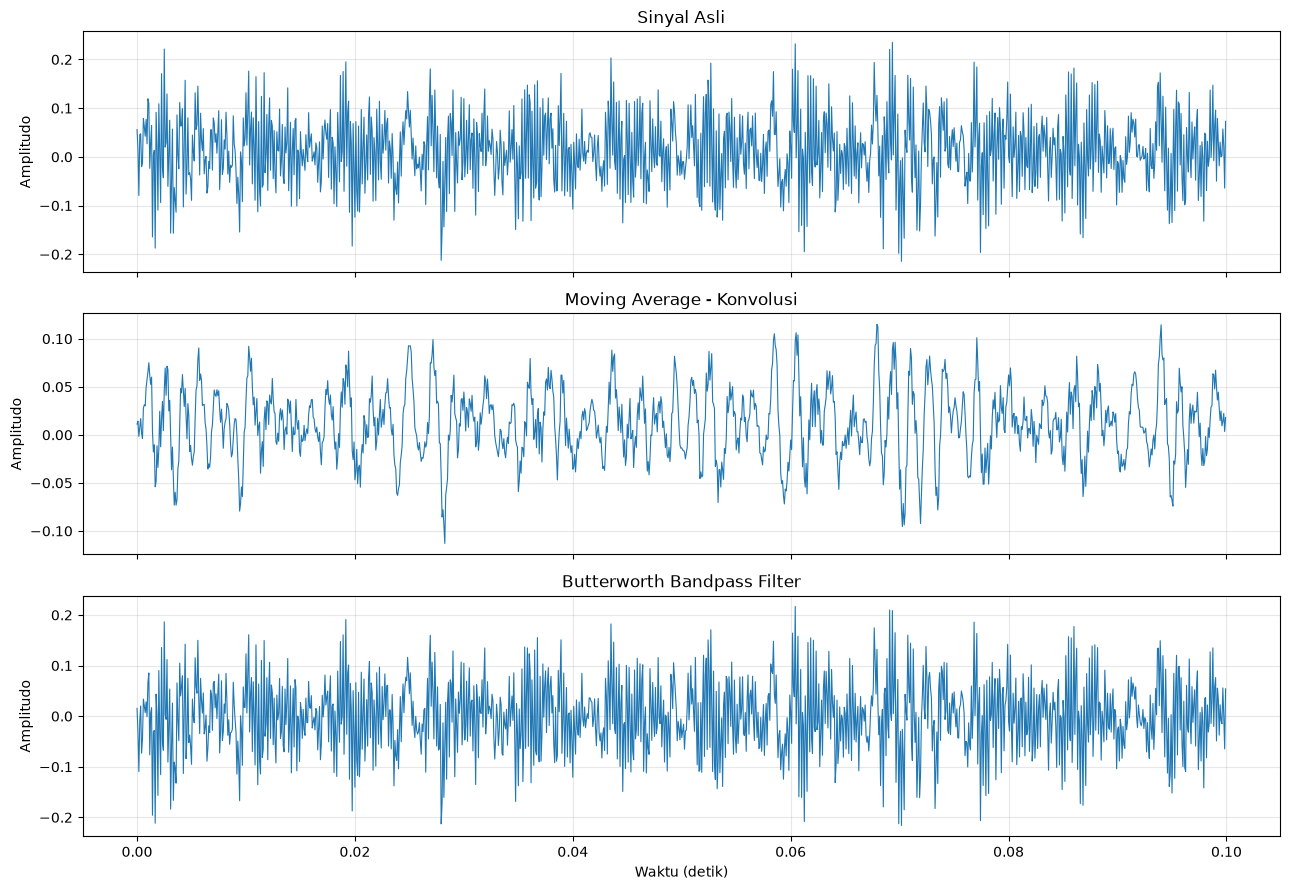

In [23]:
# Membandingkan Moving Average dan Butterworth
# Ambil sinyal Butterworth dari rekaman yang sama
butterworth_signal = (
    df[df["source_file"] == source_file]
    .sort_values("sample_index")
    ["vibration_filtered"]
    .to_numpy()[:1200]
)

fig, axes = plt.subplots(
    3, 1,
    figsize=(13, 9),
    sharex=True
)

axes[0].plot(time, signal, linewidth=0.8)
axes[0].set_title("Sinyal Asli")

axes[1].plot(
    time,
    signal_same,
    linewidth=0.8
)
axes[1].set_title(
    "Moving Average - Konvolusi"
)

axes[2].plot(
    time,
    butterworth_signal,
    linewidth=0.8
)
axes[2].set_title(
    "Butterworth Bandpass Filter"
)

for ax in axes:
    ax.set_ylabel("Amplitudo")
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Waktu (detik)")

plt.tight_layout()
plt.show()


In [24]:
print("File yang digunakan:", source_file)
print("Kondisi:", normal_df["condition"].iloc[0])
print("Beban motor:", normal_df["motor_load_hp"].iloc[0], "HP")
print("Jumlah sampel yang divisualisasikan:", len(signal))

File yang digunakan: 97.mat
Kondisi: Normal
Beban motor: 0 HP
Jumlah sampel yang divisualisasikan: 1200


# Fungsi FFT

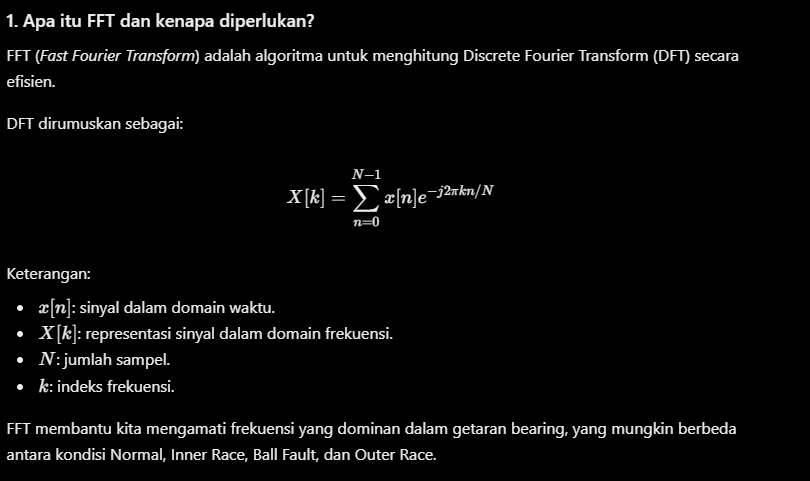

In [25]:
# Membuat fungsi FFT
from scipy.fft import rfft, rfftfreq

def calculate_fft(signal, fs=12000):
    """
    Menghitung spektrum amplitudo satu sisi
    dari sinyal getaran.
    """
    signal = np.asarray(signal, dtype=float)

    # Menghilangkan komponen DC
    signal = signal - np.mean(signal)

    N = len(signal)

    # FFT untuk sinyal real
    fft_values = rfft(signal)

    # Frekuensi setiap bin FFT
    frequencies = rfftfreq(N, d=1/fs)

    # Normalisasi amplitudo satu sisi
    amplitudes = np.abs(fft_values) / N

    if N % 2 == 0:
        amplitudes[1:-1] *= 2
    else:
        amplitudes[1:] *= 2

    return frequencies, amplitudes

print("Fungsi FFT berhasil dibuat.")


Fungsi FFT berhasil dibuat.


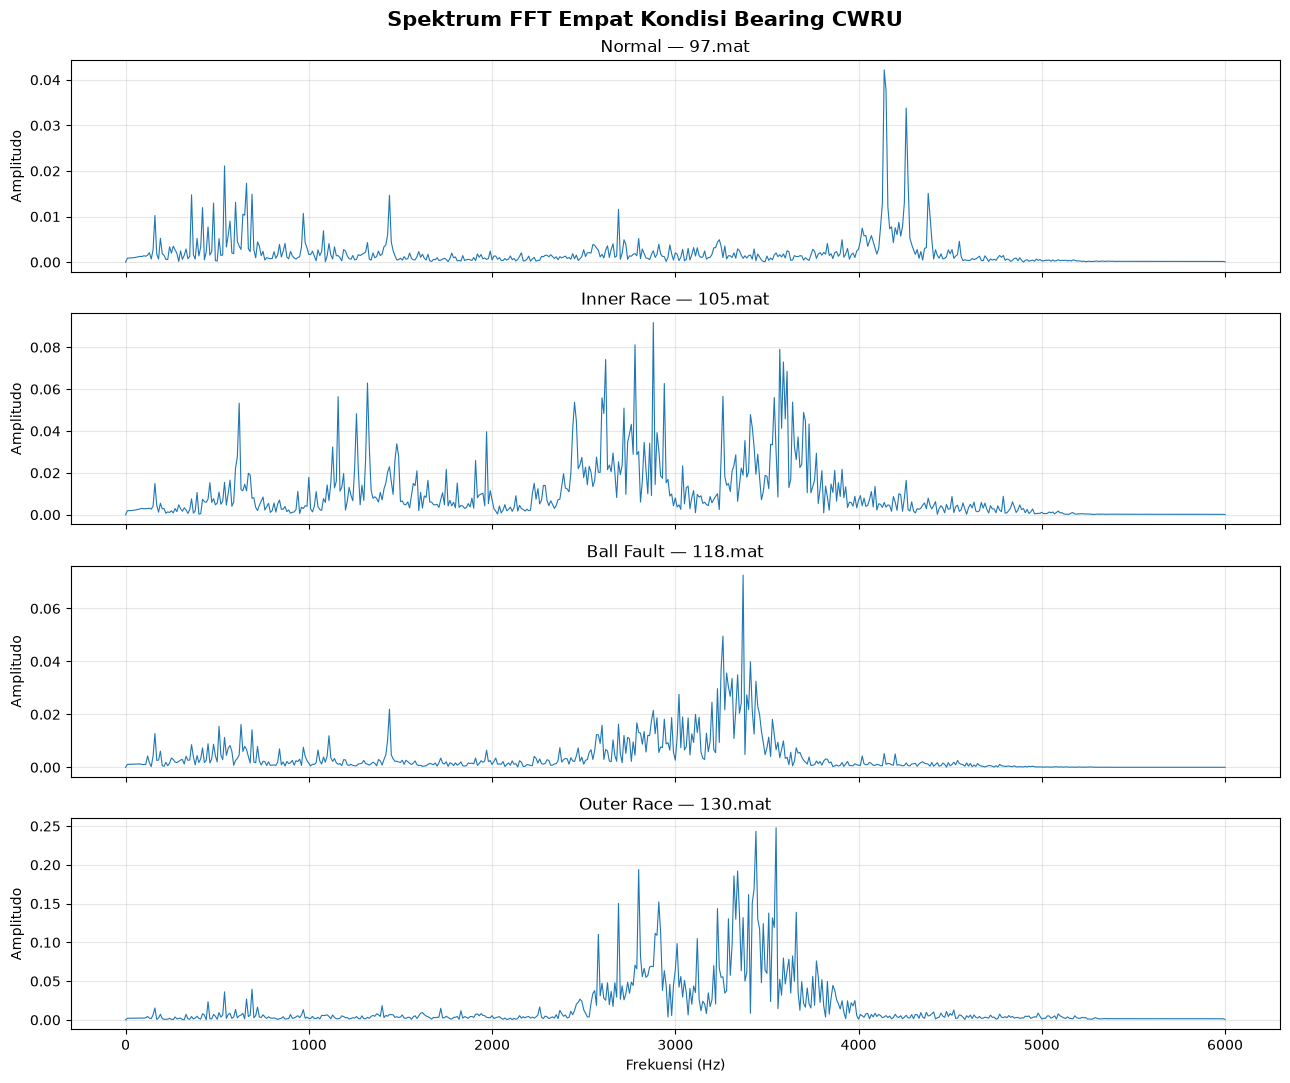

In [ ]:
# FFT empat kondisi bearing
conditions = [
    "Normal",
    "Inner Race",
    "Ball Fault",
    "Outer Race"
]

fig, axes = plt.subplots(
    4, 1,
    figsize=(13, 11),
    sharex=True
)

for ax, condition in zip(axes, conditions):

    subset = df[
        (df["condition"] == condition) &
        (df["motor_load_hp"] == 0)
    ]

    source_file = subset["source_file"].iloc[0]

    signal_df = (
        subset[subset["source_file"] == source_file]
        .sort_values("sample_index")
        .head(1200)
    )

    signal_filtered = signal_df[
        "vibration_filtered"
    ].to_numpy()

    frequencies, amplitudes = calculate_fft(
        signal_filtered,
        fs=FS
    )
=
    ax.plot(
        frequencies,
        amplitudes,
        linewidth=0.8
    )

    ax.set_title(f"{condition} — {source_file}")
    ax.set_ylabel("Amplitudo")
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Frekuensi (Hz)")

fig.suptitle(
    "Spektrum FFT Empat Kondisi Bearing CWRU",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


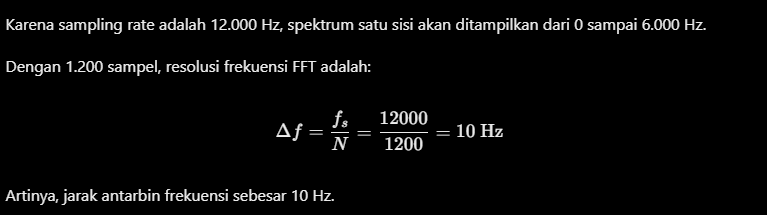

Sekarang kita periksa apakah Butterworth Bandpass benar-benar melemahkan komponen frekuensi di luar rentang 100–5.000 Hz.

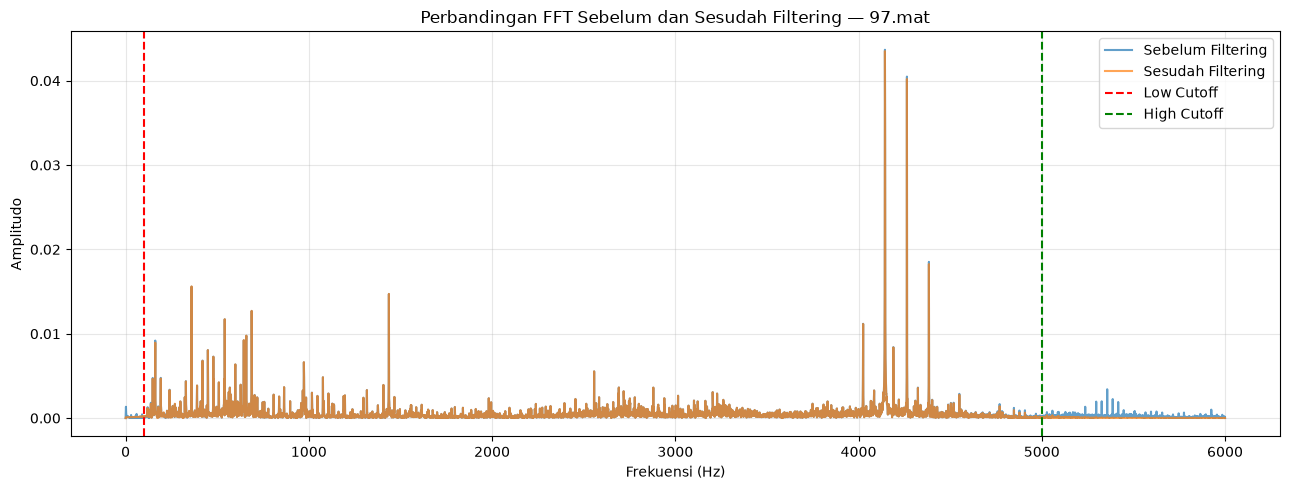

In [27]:
# erbandingan FFT sebelum dan sesudah filtering
# Contoh rekaman Normal 0 HP
subset = df[
    (df["condition"] == "Normal") &
    (df["motor_load_hp"] == 0)
]

source_file = subset["source_file"].iloc[0]

signal_df = (
    subset[subset["source_file"] == source_file]
    .sort_values("sample_index")
    .head(12000)
)

original = signal_df["vibration"].to_numpy()
filtered = signal_df["vibration_filtered"].to_numpy()

freq_before, amp_before = calculate_fft(original, FS)
freq_after, amp_after = calculate_fft(filtered, FS)

plt.figure(figsize=(13, 5))

plt.plot(
    freq_before,
    amp_before,
    label="Sebelum Filtering",
    alpha=0.7
)

plt.plot(
    freq_after,
    amp_after,
    label="Sesudah Filtering",
    alpha=0.7
)

plt.axvline(
    LOW_CUTOFF,
    linestyle="--",
    color="red",
    label="Low Cutoff"
)

plt.axvline(
    HIGH_CUTOFF,
    linestyle="--",
    color="green",
    label="High Cutoff"
)

plt.title(
    f"Perbandingan FFT Sebelum dan Sesudah Filtering — {source_file}"
)
plt.xlabel("Frekuensi (Hz)")
plt.ylabel("Amplitudo")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [28]:
# Mengidentifikasi frekuensi dominan
dominant_results = []

for condition in conditions:

    subset = df[
        (df["condition"] == condition) &
        (df["motor_load_hp"] == 0)
    ]

    source_file = subset["source_file"].iloc[0]

    signal_df = (
        subset[subset["source_file"] == source_file]
        .sort_values("sample_index")
        .head(12000)
    )

    signal_filtered = signal_df[
        "vibration_filtered"
    ].to_numpy()

    freq, amp = calculate_fft(signal_filtered, FS)

    # Abaikan frekuensi 0 Hz
    dominant_index = np.argmax(amp[1:]) + 1

    dominant_results.append({
        "Condition": condition,
        "Source File": source_file,
        "Dominant Frequency (Hz)": freq[dominant_index],
        "Peak Amplitude": amp[dominant_index]
    })

dominant_df = pd.DataFrame(dominant_results)

display(dominant_df.round(5))


,Condition,Source File,Dominant Frequency (Hz),Peak Amplitude
0,Normal,97.mat,4144.0,0.04350
1,Inner Race,105.mat,3587.0,0.09997
2,Ball Fault,118.mat,3365.0,0.03676
3,Outer Race,130.mat,3445.0,0.29235


# Analisis Hasil FFT dan Evaluasi Spektrum Frekuensi 

In [29]:
# Membuat fungsi analisis PSD
from scipy.signal import welch

def calculate_psd(signal, fs=12000):
    """
    Menghitung Power Spectral Density
    menggunakan metode Welch.
    """
    signal = np.asarray(signal, dtype=float)

    frequencies, psd = welch(
        signal,
        fs=fs,
        window="hann",
        nperseg=min(2048, len(signal)),
        noverlap=min(1024, len(signal) // 2),
        detrend="constant",
        scaling="density"
    )

    return frequencies, psd

print("Fungsi PSD berhasil dibuat.")


Fungsi PSD berhasil dibuat.


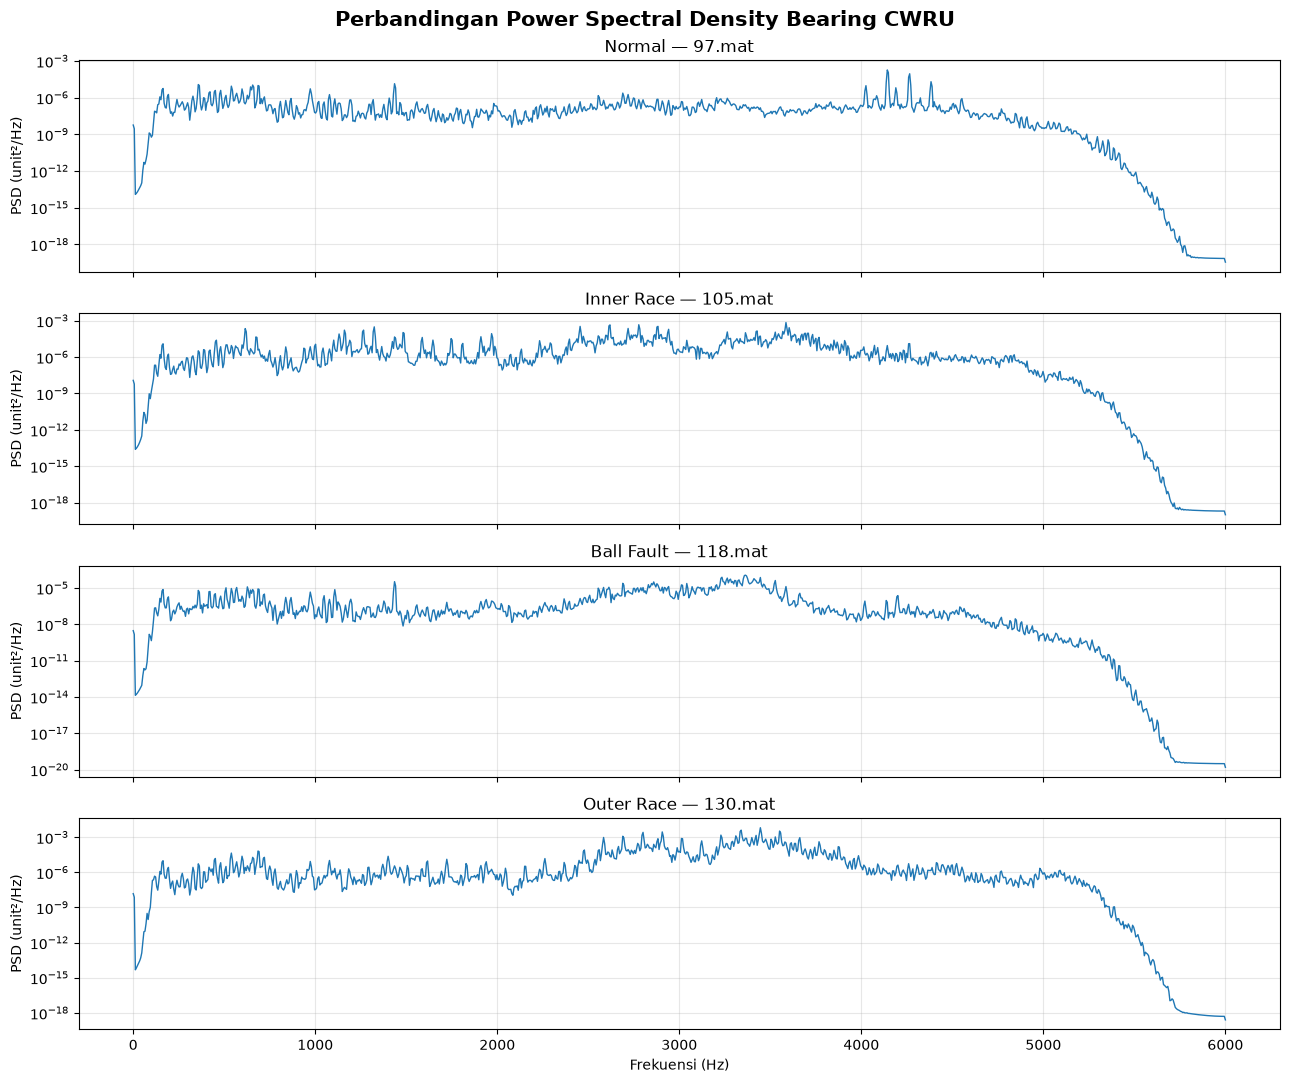

In [30]:
# Visualisasi PSD empat kondisi bearing
representative_files = {
    "Normal": "97.mat",
    "Inner Race": "105.mat",
    "Ball Fault": "118.mat",
    "Outer Race": "130.mat"
}

fig, axes = plt.subplots(
    4, 1,
    figsize=(13, 11),
    sharex=True
)

for ax, (condition, filename) in zip(
    axes, representative_files.items()
):
    subset = (
        df[df["source_file"] == filename]
        .sort_values("sample_index")
    )

    signal = subset[
        "vibration_filtered"
    ].to_numpy()[:12000]

    frequencies, psd = calculate_psd(
        signal, FS
    )

    ax.semilogy(
        frequencies,
        np.maximum(psd, 1e-20),
        linewidth=1
    )

    ax.set_title(f"{condition} — {filename}")
    ax.set_ylabel("PSD (unit²/Hz)")
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Frekuensi (Hz)")

fig.suptitle(
    "Perbandingan Power Spectral Density Bearing CWRU",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


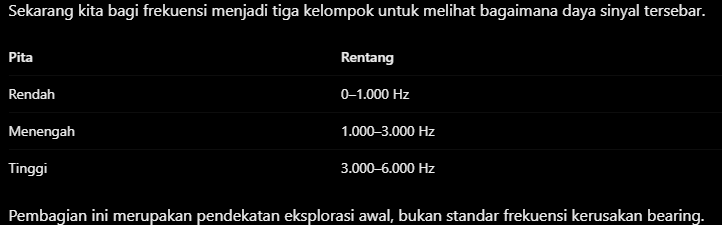

In [31]:
# Menghitung distribusi daya pada tiga pita frekuensi
from scipy.integrate import trapezoid

frequency_bands = {
    "Low": (0, 1000),
    "Mid": (1000, 3000),
    "High": (3000, 6000)
}

band_results = []

for condition, filename in representative_files.items():

    subset = (
        df[df["source_file"] == filename]
        .sort_values("sample_index")
    )

    signal = subset[
        "vibration_filtered"
    ].to_numpy()[:12000]

    frequencies, psd = calculate_psd(signal, FS)

    row = {
        "Condition": condition,
        "Source File": filename
    }

    total_power = trapezoid(psd, frequencies)

    for band_name, (low, high) in frequency_bands.items():

        mask = (
            (frequencies >= low) &
            (frequencies <= high)
        )

        band_power = trapezoid(
            psd[mask],
            frequencies[mask]
        )

        row[f"{band_name} Power"] = band_power

        row[f"{band_name} (%)"] = (
            100 * band_power / total_power
            if total_power > 0 else np.nan
        )

    band_results.append(row)

band_df = pd.DataFrame(band_results)

display(band_df.round(4))


,Condition,Source File,Low Power,Low (%),Mid Power,Mid (%),High Power,High (%)
0,Normal,97.mat,0.0010,21.2717,0.0005,9.6281,0.0034,69.0931
1,Inner Race,105.mat,0.0044,5.3204,0.0463,55.9418,0.0320,38.6704
2,Ball Fault,118.mat,0.0013,6.6227,0.0042,22.1285,0.0135,71.2474
3,Outer Race,130.mat,0.0029,0.6367,0.1171,25.4458,0.3402,73.9175


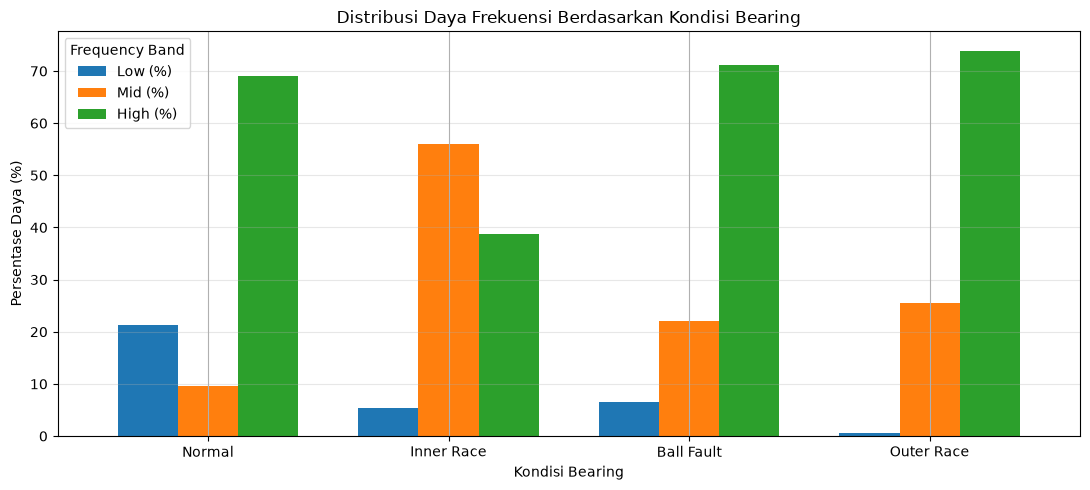

In [32]:
# Visualisasi distribusi daya frekuensi
power_columns = [
    "Low (%)",
    "Mid (%)",
    "High (%)"
]

ax = band_df.set_index("Condition")[
    power_columns
].plot(
    kind="bar",
    figsize=(11, 5),
    width=0.75
)

ax.set_title(
    "Distribusi Daya Frekuensi Berdasarkan Kondisi Bearing"
)
ax.set_xlabel("Kondisi Bearing")
ax.set_ylabel("Persentase Daya (%)")
ax.legend(title="Frequency Band")

plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [33]:
# Evaluasi daya sebelum dan sesudah filtering
filter_results = []

for condition, filename in representative_files.items():

    subset = (
        df[df["source_file"] == filename]
        .sort_values("sample_index")
        .head(12000)
    )

    original = subset["vibration"].to_numpy()
    filtered = subset["vibration_filtered"].to_numpy()

    f_before, p_before = calculate_psd(original, FS)
    f_after, p_after = calculate_psd(filtered, FS)

    power_before = trapezoid(p_before, f_before)
    power_after = trapezoid(p_after, f_after)

    change_pct = (
        100 * (power_after - power_before) / power_before
        if power_before > 0 else np.nan
    )

    filter_results.append({
        "Condition": condition,
        "Power Before": power_before,
        "Power After": power_after,
        "Change (%)": change_pct
    })

filter_evaluation = pd.DataFrame(filter_results)

display(filter_evaluation.round(6))


,Condition,Power Before,Power After,Change (%)
0,Normal,0.004959,0.004873,-1.742043
1,Inner Race,0.083096,0.082842,-0.304597
2,Ball Fault,0.019011,0.018990,-0.111267
3,Outer Race,0.463302,0.460307,-0.646477
